# Lesson 2: NumPy

One operation on a whole column of numbers.

<img src="../img/map-2.svg" width="85%" alt="">

## How to follow along, and Quizlets

You should have the notebooks with the name `lecture-workbook` open, **not these slides**. Whenever you see a quizlet, you should do the exercise in your notebook and then we will go over the answer together. You will have a a few minutes for each exercise. 

## The cost of a loop

Project 1 read 50,000 events, and you waited a moment. The full sample here is 300,000 events, and an LHC experiment records billions.

Every analysis asks the same question of every event, so the loop is always the same shape. Array programming hands that loop to fast compiled code: you write the operation once, the library applies it to the whole column.

NumPy is the shared language of scientific Python: pandas, hist, SciPy and Awkward Array all build on its arrays. Learn the moves once, use them everywhere.

## Loops and arrays

A loop handles one value at a time. An array handles the whole column.

<img src="../img/loop-vs-column.svg" width="85%" alt="">

## Programming paradigms

Paradigms are rough classifications of programming styles.

| Paradigm | The style | Where you meet it |
|:--|:--|:--|
| imperative | spell out every step, one element at a time | project 1 |
| object-oriented | bundle data with the methods that use it | lesson 3 |
| functional | pass functions to functions | `map`, comprehensions |
| array-oriented | one operation on whole arrays | this lesson |

The same job four ways: square every element.

**Imperatively**, element by element:

In [1]:
input_data = [1, 2, 3, 4, 5, 6, 7, 8, 9]
output_data = []

for x in input_data:
    output_data.append(x**2)

output_data

[1, 4, 9, 16, 25, 36, 49, 64, 81]

**Functionally**: `map` from lesson 1 calls `square` on every element, or the comprehension shorthand:

In [2]:
def square(x):
    return x**2

list(map(square, input_data))

[1, 4, 9, 16, 25, 36, 49, 64, 81]

In [3]:
[x**2 for x in input_data]

[1, 4, 9, 16, 25, 36, 49, 64, 81]

**Array-oriented**, the subject of this lesson. By the end, the whole job is one line:

```python
input_data ** 2
```

where `input_data` is an *array*, a kind of value we have not met yet.

Functional and imperative code still thinks in elements: the `x` in `square(x)` is one number. Array-oriented code has no element in sight: the variables are whole columns, and the question is how the *distribution* changes.

Every array language, from APL in the 1960s to MATLAB, R and NumPy, was built for the same job: interactive data analysis. Short questions, quick answers, at any data size.

Paradigms are styles, not laws: Python mixes them freely.

Project 1 was the imperative Higgs search, and project 2 is the same search, array-oriented.

## Arrays

An array is one block of values that all have the same type.

Everyone imports NumPy under the short name `np`.

<img src="../img/list-vs-array.svg" width="80%" alt="">

In [4]:
import numpy as np

pt = np.array([63.0, 38.1, 4.0, 54.3])
pt.dtype, pt.shape

(dtype('float64'), (4,))

## Making arrays

From a list, from a range, from nothing.

In [5]:
np.arange(5), np.linspace(0.0, 1.0, 5)

(array([0, 1, 2, 3, 4]), array([0.  , 0.25, 0.5 , 0.75, 1.  ]))

In [6]:
np.zeros(4), np.ones(3)

(array([0., 0., 0., 0.]), array([1., 1., 1.]))

## Every array has a `dtype`

One type for the whole block, and the operations follow it. `astype` converts the whole column at once.

In [7]:
counts = np.array([5, 2, 9])
counts.dtype, (counts / 2).dtype

(dtype('int64'), dtype('float64'))

In [8]:
mask = np.array([True, False, True])
mask.astype(np.int32)

array([1, 0, 1], dtype=int32)

Memory is the dtype times the count, nothing more. `astype` trades precision for half the space:

In [9]:
big = np.ones(1_000_000)
big.nbytes, big.astype(np.float32).nbytes

(8000000, 4000000)

## Quizlet 2.1 — who shares the memory?

Guess before you run: after the last line, what is in `a`?

<img src="../img/view.svg" width="70%" alt="">

In [10]:
a = np.array([63.0, 38.1, 4.0])
b = a[:2]
b[0] = 999.0
a

array([999. ,  38.1,   4. ])

A slice of an array is a *view*: the same memory under a new name. Fast, because nothing is copied — and a surprise, until you know it. `a[:2].copy()` gives you your own block. (A slice of a *list* is a copy. Python keeps you alert.)

## Arithmetic

Arithmetic applies to every element at once.

<img src="../img/elementwise.svg" width="70%" alt="">

In [11]:
pt * 2

array([126. ,  76.2,   8. , 108.6])

## Broadcasting

Shapes do not have to match: a single number is reused for every element, and a row and a column spread out into a table.

<img src="../img/broadcast.svg" width="80%" alt="">


In [12]:
pt - 20.0

array([ 43. ,  18.1, -16. ,  34.3])

**Quizlet 2.2 — broadcasting.** Before you run it: how many numbers come out — 2, 3 or 6?

In [13]:
pt2d = np.array([[63.0, 38.1, 4.0],
                 [54.3, 23.5, 52.9]])
scale = np.array([1.0, 1.0, 0.5])

pt2d * scale

array([[63.  , 38.1 ,  2.  ],
       [54.3 , 23.5 , 26.45]])

## Lists are different

A list does something else with `* 2`: it repeats itself.

**Quizlet 2.3 — lists are not arrays.** Before you run it: what does `* 2` do to a list, and to an array?

In [14]:
[63.0, 38.1, 4.0, 54.3] * 2

[63.0, 38.1, 4.0, 54.3, 63.0, 38.1, 4.0, 54.3]

## NumPy functions

NumPy functions apply to every element. Arrays of the same shape combine element by element.

The momentum along the beam is $p_z = p_T \sinh\eta$.

<img src="../img/elementwise-two.svg" width="70%" alt="">

In [15]:
eta = np.array([-0.72, -0.88, -0.32, -1.06])
pz = pt * np.sinh(eta)
pz

array([-49.38195007, -38.02602494,  -1.30195745, -68.95869711])

This holds for *any* closed-form formula: write it once with scalars in mind, hand it whole arrays, and every event is computed in one sweep.

## Quizlet 2.4 — the mass that is not there

In project 1, `mass()` took a square root. What if the number under it is negative?

Guess before you run: an error, or something else?

<img src="../img/nan-flow.svg" width="85%" alt="">


In [16]:
np.sqrt(np.array([4.0, -1.0]))

/var/folders/38/4wt92601459521ys_rqb1fm00000gn/T/ipykernel_43643/2719801553.py:1: RuntimeWarning: invalid value encountered in sqrt
  np.sqrt(np.array([4.0, -1.0]))


array([ 2., nan])

`nan` — *not a number* — with a warning, not an error. It flows silently through every later step, and `nan == nan` is `False`. When a mass distribution has a hole, look for a `nan` upstream.

## Speed

The array version is much faster than the loop.

`%timeit` runs a line many times and reports the average time.

In [17]:
big = np.arange(1_000_000)
%timeit [x * 2 for x in big]

35.2 ms ± 1.09 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [18]:
%timeit big * 2

485 μs ± 21.7 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


## Why is the array version fast?

There are essentially two kinds of languages, and Python is one of the slow ones.

<img src="../img/benchmark-games-2023.svg" width="70%" alt="">

Python (and Ruby, Perl, Lua, PHP...) allow all data types to be dynamic, so that a list or a dict can contain any type of data.

But this means that before each operation, data types need to be checked to see if the operation is possible.

Over and over again, for every step of a loop over a million elements.

Memory layout of a Python list.

<img src="../img/python-list-layout.svg" width="70%" alt="">

Memory layout of a NumPy array.

<img src="../img/python-array-layout.svg" width="70%" alt="">

Dynamic types are usually the main reason why pure Python is slow, but there are others (garbage collector, virtual machine, pointer chasing...).

Most of these are addressed by a compiled library like NumPy, in which the loops over large datasets are in compiled code.

## Masks

A comparison on an array gives a mask: one `True` or `False` per element.

In [19]:
mask = pt > 20
mask

array([ True,  True, False,  True])

## Selecting with a mask

A mask inside square brackets keeps the `True` entries.

<img src="../img/mask.svg" width="70%" alt="">

In [20]:
pt[mask]

array([63. , 38.1, 54.3])

## Indexing with positions

Square brackets also accept a list of positions: any order, repeats allowed. A mask asks "which pass?", positions say "these, in this order".

In [21]:
pt[np.array([2, 0, 0])]

array([ 4., 63., 63.])

## Masks across arrays

A mask made from one array can select from another.

Position 0 in `pt` and position 0 in `eta` describe the same muon.

<img src="../img/mask-other.svg" width="70%" alt="">

In [22]:
eta[mask]

array([-0.72, -0.88, -1.06])

Indexing with positions turns coded data back into readable data. `np.unique` splits a text into its vocabulary and the position of each word in it:

In [23]:
text = """
WOULD YOU LIKE GREEN EGGS AND HAM?

I DO NOT LIKE THEM, SAM-I-AM.
I DO NOT LIKE GREEN EGGS AND HAM.

WOULD YOU LIKE THEM HERE OR THERE?

I WOULD NOT LIKE THEM HERE OR THERE.
I WOULD NOT LIKE THEM ANYWHERE.
I DO NOT LIKE GREEN EGGS AND HAM.
I DO NOT LIKE THEM, SAM-I-AM.

WOULD YOU LIKE THEM IN A HOUSE?
WOULD YOU LIKE THEN WITH A MOUSE?

I DO NOT LIKE THEM IN A HOUSE.
I DO NOT LIKE THEM WITH A MOUSE.
I DO NOT LIKE THEM HERE OR THERE.
I DO NOT LIKE THEM ANYWHERE.
I DO NOT LIKE GREEN EGGS AND HAM.
I DO NOT LIKE THEM, SAM-I-AM.

WOULD YOU EAT THEM IN A BOX?
WOULD YOU EAT THEM WITH A FOX?

NOT IN A BOX. NOT WITH A FOX.
NOT IN A HOUSE. NOT WITH A MOUSE.
I WOULD NOT EAT THEM HERE OR THERE.
I WOULD NOT EAT THEM ANYWHERE.
I WOULD NOT EAT GREEN EGGS AND HAM.
I DO NOT LIKE THEM, SAM-I-AM.
"""
words = np.array(text.replace(",", " ").replace(".", " ").replace("?", " ").replace("!", " ").replace("-", " ").split())
dictionary, index = np.unique(words, return_inverse=True)

In [24]:
dictionary

array(['A', 'AM', 'AND', 'ANYWHERE', 'BOX', 'DO', 'EAT', 'EGGS', 'FOX',
       'GREEN', 'HAM', 'HERE', 'HOUSE', 'I', 'IN', 'LIKE', 'MOUSE', 'NOT',
       'OR', 'SAM', 'THEM', 'THEN', 'THERE', 'WITH', 'WOULD', 'YOU'],
      dtype='<U8')

In [25]:
index

array([24, 25, 15,  9,  7,  2, 10, 13,  5, 17, 15, 20, 19, 13,  1, 13,  5,
       17, 15,  9,  7,  2, 10, 24, 25, 15, 20, 11, 18, 22, 13, 24, 17, 15,
       20, 11, 18, 22, 13, 24, 17, 15, 20,  3, 13,  5, 17, 15,  9,  7,  2,
       10, 13,  5, 17, 15, 20, 19, 13,  1, 24, 25, 15, 20, 14,  0, 12, 24,
       25, 15, 21, 23,  0, 16, 13,  5, 17, 15, 20, 14,  0, 12, 13,  5, 17,
       15, 20, 23,  0, 16, 13,  5, 17, 15, 20, 11, 18, 22, 13,  5, 17, 15,
       20,  3, 13,  5, 17, 15,  9,  7,  2, 10, 13,  5, 17, 15, 20, 19, 13,
        1, 24, 25,  6, 20, 14,  0,  4, 24, 25,  6, 20, 23,  0,  8, 17, 14,
        0,  4, 17, 23,  0,  8, 17, 14,  0, 12, 17, 23,  0, 16, 13, 24, 17,
        6, 20, 11, 18, 22, 13, 24, 17,  6, 20,  3, 13, 24, 17,  6,  9,  7,
        2, 10, 13,  5, 17, 15, 20, 19, 13,  1])

**Quizlet 2.5** — What's going to happen?

In [26]:
dictionary[index]

array(['WOULD', 'YOU', 'LIKE', 'GREEN', 'EGGS', 'AND', 'HAM', 'I', 'DO',
       'NOT', 'LIKE', 'THEM', 'SAM', 'I', 'AM', 'I', 'DO', 'NOT', 'LIKE',
       'GREEN', 'EGGS', 'AND', 'HAM', 'WOULD', 'YOU', 'LIKE', 'THEM',
       'HERE', 'OR', 'THERE', 'I', 'WOULD', 'NOT', 'LIKE', 'THEM', 'HERE',
       'OR', 'THERE', 'I', 'WOULD', 'NOT', 'LIKE', 'THEM', 'ANYWHERE',
       'I', 'DO', 'NOT', 'LIKE', 'GREEN', 'EGGS', 'AND', 'HAM', 'I', 'DO',
       'NOT', 'LIKE', 'THEM', 'SAM', 'I', 'AM', 'WOULD', 'YOU', 'LIKE',
       'THEM', 'IN', 'A', 'HOUSE', 'WOULD', 'YOU', 'LIKE', 'THEN', 'WITH',
       'A', 'MOUSE', 'I', 'DO', 'NOT', 'LIKE', 'THEM', 'IN', 'A', 'HOUSE',
       'I', 'DO', 'NOT', 'LIKE', 'THEM', 'WITH', 'A', 'MOUSE', 'I', 'DO',
       'NOT', 'LIKE', 'THEM', 'HERE', 'OR', 'THERE', 'I', 'DO', 'NOT',
       'LIKE', 'THEM', 'ANYWHERE', 'I', 'DO', 'NOT', 'LIKE', 'GREEN',
       'EGGS', 'AND', 'HAM', 'I', 'DO', 'NOT', 'LIKE', 'THEM', 'SAM', 'I',
       'AM', 'WOULD', 'YOU', 'EAT', 'THEM', 'IN', 

<details>
    <summary><b>Hint...</b></summary>

```
index             : positions in corpus (0, 1, 2, ...) → integer codes
dictionary        : integer codes                      → words

dictionary[index] : positions in corpus (0, 1, 2, ...) → words
```

</details>

## Combining masks

Combine masks with `&` (and) and `|` (or). Put each condition in parentheses.

In [27]:
(pt > 20) & (np.abs(eta) < 1.0)

array([ True,  True, False, False])

## What does not work

The words `and` and `or` do not work on arrays, and neither does `12 < x < 120`.

Read the last line of the error.

**Quizlet 2.6 — fix the mistake.** This should count the particles passing both cuts. Fix it.

In [66]:
(pt > 20) and (np.abs(eta) < 1.0)

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

## Counting

Counting the `True` values counts what passes.

`True` counts as 1 and `False` as 0. The mean of a mask is the fraction that passes.

In [29]:
print(mask.sum(), mask.mean())

3 0.75


**Quizlet 2.7 — predict the count.** How many particles pass $p_T > 20$ *and* $|\eta| < 1$? Decide first, then check:

In [30]:
((pt > 20) & (np.abs(eta) < 1.0)).sum()

np.int64(2)

## Reductions

A reduction turns many values into one.

<img src="../img/reduce.svg" width="75%" alt="">

In [31]:
print(pt.max(), pt.min(), len(pt))

63.0 4.0 4


## Which one, not how big

`max` says how big. `argmax` says *where*. The position then looks up anything else about the winner.

<img src="../img/argmax.svg" width="80%" alt="">


In [32]:
i = np.argmax(pt)
i, eta[i]

(np.int64(0), np.float64(-0.72))

## `np.minimum` and `np.maximum`

`np.minimum` and `np.maximum` compare two arrays element by element.

In [33]:
other = np.array([50.0, 20.0, 10.0, 60.0])
np.minimum(pt, other)

array([50. , 20. ,  4. , 54.3])

## Two dimensions

An array can have two dimensions. Writing a list of lists makes one: each inner list becomes a row of a grid. `axis` names the dimension that an operation acts on.

Here each row is an event. `axis=1` leaves one value per event.

<img src="../img/axis.svg" width="70%" alt="">

**Quizlet 2.8 — `axis`.** Two rows, three columns. Before you run it: how many numbers does each sum give?

In [34]:
pt2d = np.array([[63.0, 38.1, 4.0],
                 [54.3, 23.5, 52.9]])
pt2d.sum(axis=1)

array([105.1, 130.7])

`[row, column]` picks one value, and `:` means the whole axis. `pt2d[:, 0]` is the first column: one value per row.

In [35]:
pt2d[0, 2], pt2d[:, 0]

(np.float64(4.0), array([63. , 54.3]))

A grid does not have to be typed as nested lists: `reshape` folds a flat array into one. The six values stay the same six values, in a new shape, and nothing is copied.

In [36]:
np.arange(6).reshape(2, 3)

array([[0, 1, 2],
       [3, 4, 5]])

## Invent data to test with

A generator with a seed gives the same "random" numbers on every run, so a test you write today fails the same way tomorrow.

In [37]:
rng = np.random.default_rng(1)
rng.normal(91.2, 2.5, 5)

array([92.06396048, 93.25404536, 92.02609269, 87.94210692, 93.46338967])

## Histograms

The `hist` library builds, fills and plots a histogram.

`Reg(50, 0, 100)` means 50 bins of equal width from 0 to 100.

<img src="../img/histogram.svg" width="65%" alt="">

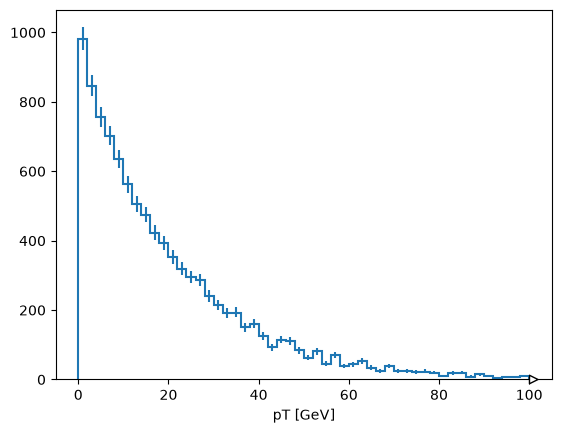

In [38]:
import hist

h = hist.Hist.new.Reg(50, 0, 100, label="pT [GeV]").Double()
h.fill(np.random.default_rng(1).exponential(20, 10_000))
h.plot();

## Quizlet 2.9 — guess the shape

Array-oriented languages bring data *distributions* to the foreground.

In [39]:
from hist import Hist  # histogram library

Given a large dataset...

In [40]:
dataset = np.random.normal(0, 1, 1000000)  # one MILLION data points

How are the data _distributed_?

In [41]:
Hist.new.Reg(100, -5, 5).Double().fill(dataset)

Hist(Regular(100, -5, 5, label='Axis 0'), storage=Double()) # Sum: 999999.0 (1000000.0 with flow)

What happens if we apply a function to _all values in the distribution_?

In [42]:
dataset2 = dataset**2

In [43]:
Hist.new.Reg(100, -1, 10).Double().fill(dataset2)

Hist(Regular(100, -1, 10, label='Axis 0'), storage=Double()) # Sum: 998441.0 (1000000.0 with flow)

**Quizlet 2.9** — Can anyone guess what this distribution will look like?

In [44]:
dataset3 = np.sin(1/dataset2)

(I can't.)

In [45]:
Hist.new.Reg(100, -1, 1).Double().fill(dataset3)

Hist(Regular(100, -1, 1, label='Axis 0'), storage=Double()) # Sum: 1000000.0

## Quizlet 2.10 — guess the shape (two dice)

One die rolls flat: every face equally often. What does the *sum of two* dice look like — still flat?

In [46]:
rolls = rng.integers(1, 7, 100_000) + rng.integers(1, 7, 100_000)
Hist.new.Reg(11, 1.5, 12.5, label="sum of two dice").Double().fill(rolls)

Hist(Regular(11, 1.5, 12.5, label='sum of two dice'), storage=Double()) # Sum: 100000.0

Sums pile up in the middle: one way to roll 2, six ways to roll 7. Add more dice and the triangle becomes the bell curve — most measurement noise is a sum of many small effects.

## The NumPy toolbox

| Tool | What it does |
|:--|:--|
| elementwise operations | one formula, every element |
| broadcasting | a number, or a smaller shape, reused |
| slicing | ranges, steps, several dimensions |
| masks | keep what passes a condition |
| integer arrays | pick by position, any order |
| `reshape` | the same values, a new shape |
| reductions | many values to one, or one per row |

And the wider world on one page:

<img src="../img/Numpy_Python_Cheat_Sheet.svg" width="90%" alt="">

## How to think in arrays

The best way to learn is by solving problems.
Quizlets 2.11 to 2.16, roughly in rising order. Try each one in the workbook before its solution slide.

### Quizlet 2.11 — hit the target

`m` is 5 × 6. Find the single slice `m[?, ?]` that gives

```python
[[ 4,  5],
 [28, 29]]
```

In [47]:
m = np.arange(30).reshape(5, 6)
m

array([[ 0,  1,  2,  3,  4,  5],
       [ 6,  7,  8,  9, 10, 11],
       [12, 13, 14, 15, 16, 17],
       [18, 19, 20, 21, 22, 23],
       [24, 25, 26, 27, 28, 29]])

#### Solution to quizlet 2.11

Rows in steps of four, columns from four onward.

In [48]:
m[::4, 4:]

array([[ 4,  5],
       [28, 29]])

### Quizlet 2.12 — the spaces between

Compute the size of the spaces between consecutive elements.

<img src="../img/flat-operation.svg" width="40%" alt=""> <img src="../img/shifted-operation.svg" width="40%" alt="">

In [49]:
array = np.array([1.1, 2.2, 3.3, 4.4, 5.5, 6.6, 7.7, 8.8, 9.9])

#### Solution to quizlet 2.12

A shifted slice against an unshifted one — or the function NumPy compiled in.

In [50]:
array[1:] - array[:-1]

array([1.1, 1.1, 1.1, 1.1, 1.1, 1.1, 1.1, 1.1])

In [51]:
np.diff(array)

array([1.1, 1.1, 1.1, 1.1, 1.1, 1.1, 1.1, 1.1])

### Quizlet 2.13 — the length of a curve

`plt.plot` draws one array against another. How long is this curve?

<img src="../img/length-by-segment.svg" width="50%" alt="">

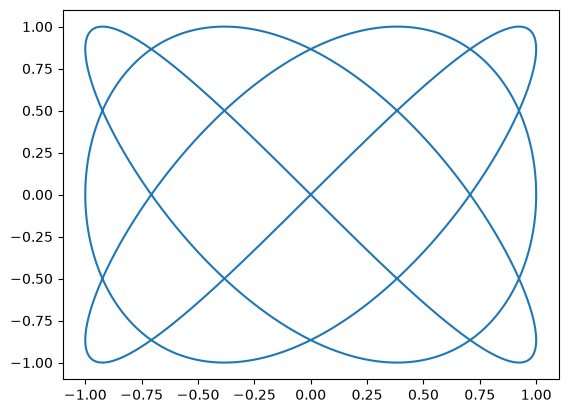

In [52]:
import matplotlib.pyplot as plt

t = np.linspace(0, 2 * np.pi, 10000)
x = np.sin(3 * t)
y = np.sin(4 * t)

plt.plot(x, y);

#### Solution to quizlet 2.13

Every step at once, Pythagoras on the steps, one sum.

In [53]:
np.sum(np.sqrt((x[1:] - x[:-1])**2 + (y[1:] - y[:-1])**2))

np.float64(21.23721056899146)

### Quizlet 2.14 — slice in three dimensions

You can select items of a 3D array,

<img src="../img/array3d-highlight1.svg" width="25%" alt="">

with `array3d[:, 1:, 1:]`. Write the slice that selects these elements:

<img src="../img/array3d-highlight2.svg" width="25%" alt="">

In [54]:
array3d = np.arange(2 * 3 * 5).reshape(2, 3, 5)
array3d

array([[[ 0,  1,  2,  3,  4],
        [ 5,  6,  7,  8,  9],
        [10, 11, 12, 13, 14]],

       [[15, 16, 17, 18, 19],
        [20, 21, 22, 23, 24],
        [25, 26, 27, 28, 29]]])

#### Solution to quizlet 2.14

Keep the first dimension (length 1), or reduce it away. Both are right.

In [55]:
array3d[:1, :, 2:]

array([[[ 2,  3,  4],
        [ 7,  8,  9],
        [12, 13, 14]]])

In [56]:
array3d[0, :, 2:]

array([[ 2,  3,  4],
       [ 7,  8,  9],
       [12, 13, 14]])

### Quizlet 2.15 — shrink a photograph

Scale this image down by a factor of 64 on both sides, using only [np.reshape](https://numpy.org/doc/stable/reference/generated/numpy.reshape.html), [np.mean](https://numpy.org/doc/stable/reference/generated/numpy.mean.html), and [np.ndarray.astype](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.astype.html).

In [57]:
import matplotlib.image

image = matplotlib.image.imread("../data/sun-shines-in-CMS.jpg")
image.shape

(1920, 2560, 3)

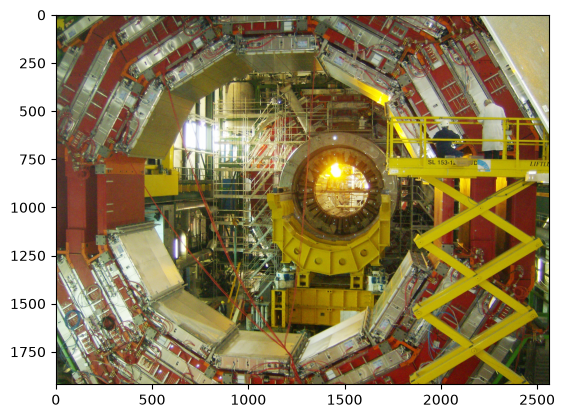

In [58]:
plt.imshow(image);

1920 rows, 2560 columns, and the third axis is for (red, green, blue), all `np.uint8`.

Your strategy should be to reshape the array, such that the dimension of length `1920` becomes two new dimensions of length `1920 // 64` and `64` and the dimension of length `2560` becomes two new dimensions of length `2560 // 64` and `64`. Then average over each of the dimensions of length `64`.

The shape should change as

$$\left(1920, 2560, 3\right) \to \left(\frac{1920}{64}, 64, \frac{2560}{64}, 64, 3\right) \to \left(\frac{1920}{64}, \frac{2560}{64}, 3\right)$$

and then you need to turn the floating-point dtype back into unsigned 8-bit integers with [np.ndarray.astype](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.astype.html).

#### Solution to quizlet 2.15

In NumPy, the shapes of arrays are fluid. An array can be reshaped from 3 dimensional to 5 dimensional as long as the number of items is unchanged.

Reshaping provides new axes for reducers like [np.mean](https://numpy.org/doc/stable/reference/generated/numpy.mean.html) to apply.

Be sure to average over axis 3 before axis 1, since reduction removes an axis, changing the numbering of later axes.

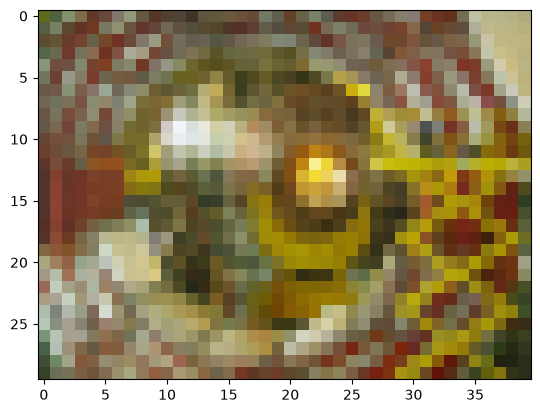

In [59]:
resampled = np.mean(
    np.mean(
        image.reshape(1920 // 64, 64, 2560 // 64, 64, 3),
        axis=3,
    ),
    axis=1,
)

plt.imshow(resampled.astype(np.uint8));

Or alternatively, use negative axis numbers and do it in the other order.

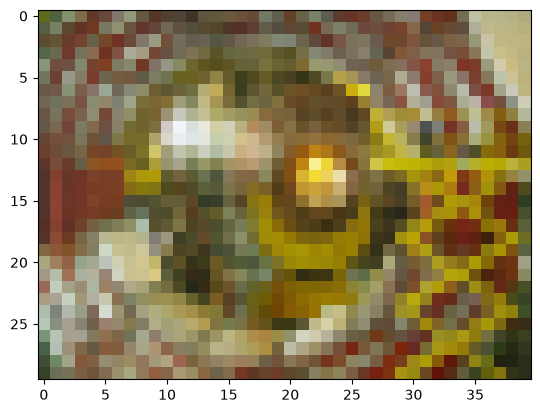

In [60]:
resampled = np.mean(
    np.mean(
        image.reshape(1920 // 64, 64, 2560 // 64, 64, 3),
        axis=-4,
    ),
    axis=-2,
)

plt.imshow(resampled.astype(np.uint8));

Or as a third option, use `keepdims=True` to keep the axis numbering from changing and only remove the length 1 dimensions after all reductions are done.

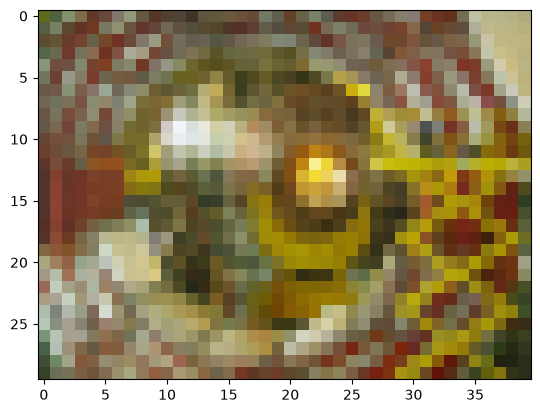

In [61]:
resampled = np.mean(
    np.mean(
        image.reshape(1920 // 64, 64, 2560 // 64, 64, 3),
        axis=1,
        keepdims=True,
    ),
    axis=3,
    keepdims=True,
).reshape(1920 // 64, 2560 // 64, 3)

plt.imshow(resampled.astype(np.uint8));

### Quizlet 2.16 — the bytes are backwards

ROOT files store their floats big-endian; your machine is little-endian. Viewed naively, five ordinary numbers look broken:

<img src="../img/big-little-endian.svg" width="75%" alt="">

In [62]:
raw = np.arange(5, dtype=">f4").tobytes()
as_bytes = np.frombuffer(raw, np.uint8)
as_bytes.view(np.float32)

array([0.0000e+00, 4.6006e-41, 8.9683e-44, 2.3049e-41, 4.6007e-41],
      dtype=float32)

Fix it: reverse the bytes *in groups of four*, using only `reshape` and a slice.

#### Solution to quizlet 2.16

A short-lived axis expresses "groups of four", and a negative-step slice reverses each group.

In [63]:
as_bytes.reshape(-1, 4)[:, ::-1].reshape(-1).view(np.float32)

array([0., 1., 2., 3., 4.], dtype=float32)

## Now: project 2.

[project-higgs.ipynb](project-higgs.ipynb): Higgs decay combinatorics, on whole columns.

<img src="../img/lepton-columns.svg" width="65%" alt="">